# Knoxville Flock Search Audit Analysis

**Question:** How does Knoxville PD use Flock cameras to search for vehicles, and what reasons do they give?

This notebook looks at 71,501 search records: what reasons officers typed in, how those reasons changed over time, and when searches happen.

**Quick notes before you read:**
- Each row = one search record, not one crime or one car.
- The "reason" is whatever text was typed in. It doesn't prove a crime happened.
- Most of the analysis skips the "Malformed / Unintelligible" reasons (text that didn't make sense), so percentages are out of the remaining ~37,700 usable records.
- Times are shown in Knoxville local time.


## 1. Load the data
Just pulling in the original Knoxville file and the categorized version (same data, but reasons sorted into categories).


In [3]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def load_knoxville_file(filename, folder_name):
    search_roots = [Path.cwd(), *list(Path.cwd().parents)[:2]]

    for root in search_roots:
        matches = [
            path for path in root.rglob(filename)
            if not any(part.startswith(".") for part in path.parts)
            and "__MACOSX" not in path.parts
        ]
        if matches:
            preferred = [path for path in matches if path.parent.name == folder_name]
            selected = sorted(preferred or matches, key=lambda path: (len(path.parts), str(path)))[0]
            return pd.read_csv(selected, low_memory=False), str(selected)

    for root in search_roots:
        archives = list(root.glob("NoFlockin"))
        for archive in archives:
            with ZipFile(archive) as zipped:
                suffix = f"/{folder_name}/{filename}"
                members = [
                    name for name in zipped.namelist()
                    if name.endswith(suffix) and not name.startswith("__MACOSX/")
                ]
                if members:
                    member = sorted(members, key=len)[0]
                    data = pd.read_csv(BytesIO(zipped.read(member)), low_memory=False)
                    return data, f"{archive}!/{member}"

    raise FileNotFoundError(
        f"Could not find {filename}. Place the NoFlockin folder or NoFlockin.zip "
        "in or near the notebook folder."
    )


original_df, original_source = load_knoxville_file("Knoxville.csv", "Datasets")
df_cat, categorized_source = load_knoxville_file("Knoxville_categorized.csv", "categorized_output")

print("Original records:", f"{len(original_df):,}")
print("Categorized records:", f"{len(df_cat):,}")
print("Categorized columns:", len(df_cat.columns))

Original records: 71,501
Categorized records: 71,501
Categorized columns: 27


## 2. Make sure the two files match
Before trusting the categories, check that the categorized file has the same records as the original — same IDs, same reason text, no duplicates.


In [4]:
required_columns = ["id", "reason", "reason_normalized", "reason_category", "search_time_utc"]
missing_columns = [column for column in required_columns if column not in df_cat.columns]

if missing_columns:
    raise ValueError(f"The categorized dataset is missing required columns: {missing_columns}")

original_duplicate_ids = int(original_df["id"].duplicated().sum())
categorized_duplicate_ids = int(df_cat["id"].duplicated().sum())

comparison = original_df[["id", "reason"]].merge(
    df_cat[["id", "reason"]],
    on="id",
    how="outer",
    suffixes=("_original", "_categorized"),
    indicator=True
)

matched = comparison[comparison["_merge"] == "both"]
reason_mismatches = int(
    matched["reason_original"].fillna("<MISSING>").astype(str).ne(
        matched["reason_categorized"].fillna("<MISSING>").astype(str)
    ).sum()
)

integrity_summary = pd.DataFrame({
    "Check": [
        "Original record count",
        "Categorized record count",
        "Duplicate IDs in original",
        "Duplicate IDs in categorized file",
        "IDs present in both files",
        "IDs only in original file",
        "IDs only in categorized file",
        "Original reason mismatches"
    ],
    "Result": [
        f"{len(original_df):,}",
        f"{len(df_cat):,}",
        f"{original_duplicate_ids:,}",
        f"{categorized_duplicate_ids:,}",
        f"{(comparison['_merge'] == 'both').sum():,}",
        f"{(comparison['_merge'] == 'left_only').sum():,}",
        f"{(comparison['_merge'] == 'right_only').sum():,}",
        f"{reason_mismatches:,}"
    ]
})

display(integrity_summary)

,Check,Result
0,Original record count,"71,501"
1,Categorized record count,"71,501"
2,Duplicate IDs in original,0
3,Duplicate IDs in categorized file,0
4,IDs present in both files,"71,501"
5,IDs only in original file,0
6,IDs only in categorized file,0
7,Original reason mismatches,0


Everything matches: same record count, no duplicate IDs, no mismatched reasons. Good to move on.


## 3. Set up the main dataset
From here on, we drop the "Malformed / Unintelligible" records (reasons that were blank or didn't make sense) and work with the rest.


In [5]:
analysis_df = df_cat[
    df_cat["reason_category"].ne("Malformed / Unintelligible")
].copy()

analysis_df["search_time"] = pd.to_datetime(
    analysis_df["search_time_utc"],
    utc=True,
    errors="coerce"
).dt.tz_convert("America/New_York")

time_df = analysis_df.dropna(subset=["search_time"]).copy()
time_df["month"] = time_df["search_time"].dt.strftime("%Y-%m")
time_df["date"] = time_df["search_time"].dt.strftime("%Y-%m-%d")
time_df["hour"] = time_df["search_time"].dt.hour
time_df["weekday"] = time_df["search_time"].dt.day_name()

overview = pd.DataFrame({
    "Measure": [
        "All records in original dataset",
        "Records in categorized analysis group",
        "Records with valid search timestamps",
        "Categories in analysis group",
        "First recorded search",
        "Last recorded search"
    ],
    "Value": [
        f"{len(original_df):,}",
        f"{len(analysis_df):,}",
        f"{len(time_df):,}",
        f"{analysis_df['reason_category'].nunique():,}",
        time_df["search_time"].min().strftime("%Y-%m-%d %I:%M %p %Z"),
        time_df["search_time"].max().strftime("%Y-%m-%d %I:%M %p %Z")
    ]
})

display(overview)

,Measure,Value
0,All records in original dataset,"71,501"
1,Records in categorized analysis group,"37,696"
2,Records with valid search timestamps,"37,696"
3,Categories in analysis group,12
4,First recorded search,2022-03-14 07:57 PM EDT
5,Last recorded search,2025-12-31 03:23 PM EST


## 4. What are the most common reasons for a search?


,Category,Records,Percentage
0,General Investigation,12402,32.90
1,BOLO / Suspect Vehicle,7385,19.59
2,Warrant / Wanted Person,5930,15.73
3,No Offense Stated / Redacted,3306,8.77
4,Drug Investigation,2451,6.50
5,Violent / Sexual Crime,2131,5.65
6,Stolen Vehicle / MVT,1575,4.18
7,Property Crime,917,2.43
8,Routine / Administrative / Test,824,2.19
9,Traffic / Crash,481,1.28


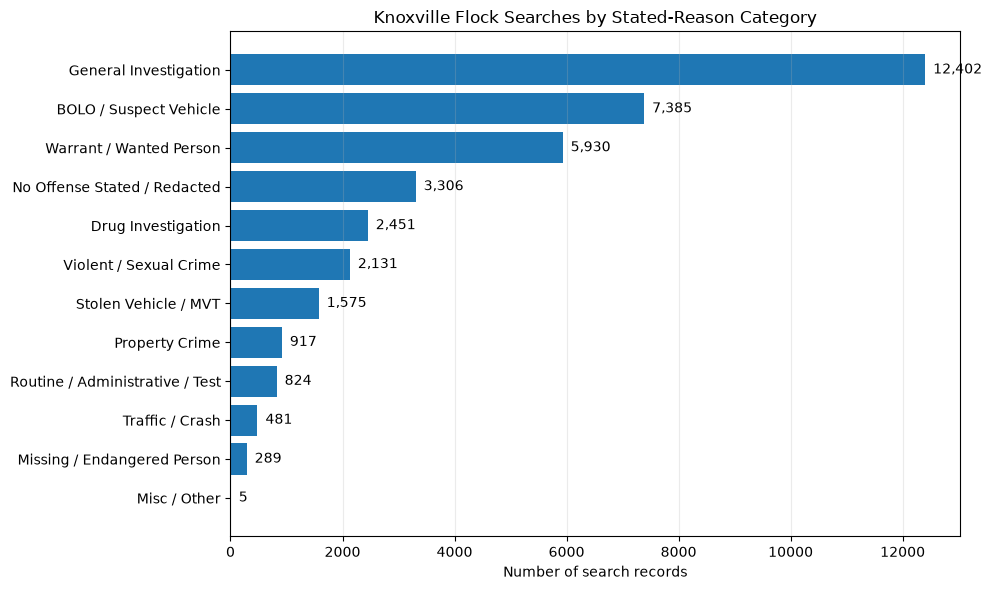

The most common category is General Investigation (12,402 records, 32.90%).
The least common category is Misc / Other (5 records, 0.01%).


In [6]:
reason_counts = analysis_df["reason_category"].value_counts()
reason_summary = reason_counts.rename_axis("Category").reset_index(name="Records")
reason_summary["Percentage"] = (
    reason_summary["Records"] / len(analysis_df) * 100
).round(2)
reason_summary = reason_summary.sort_values("Records", ascending=False).reset_index(drop=True)

display(reason_summary)

fig, ax = plt.subplots(figsize=(10, 6))
plot_data = reason_summary.sort_values("Records")
ax.barh(plot_data["Category"], plot_data["Records"])
ax.set_title("Knoxville Flock Searches by Stated-Reason Category")
ax.set_xlabel("Number of search records")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
for position, value in enumerate(plot_data["Records"]):
    ax.text(value, position, f"  {value:,}", va="center")
plt.tight_layout()
plt.show()

print(
    f"The most common category is {reason_summary.iloc[0]['Category']} "
    f"({reason_summary.iloc[0]['Records']:,} records, "
    f"{reason_summary.iloc[0]['Percentage']:.2f}%)."
)
print(
    f"The least common category is {reason_summary.iloc[-1]['Category']} "
    f"({reason_summary.iloc[-1]['Records']:,} records, "
    f"{reason_summary.iloc[-1]['Percentage']:.2f}%)."
)

**Takeaway:** General Investigation is the #1 reason, then BOLO/Suspect Vehicle, then Warrant/Wanted Person. Those three make up about two-thirds of all searches. These are just the labels officers gave — not a crime count.


## 5. Zooming into the exact words used
The category chart is the big picture. Here we look at the actual short text officers entered (like "inv" or "bolo") to see the specific labels behind each category.


Most frequent normalized reason labels


,reason_category,reason_normalized,Occurrences,Share of analysis group
0,General Investigation,inv,9595,25.45
1,BOLO / Suspect Vehicle,suspect,3184,8.45
2,Warrant / Wanted Person,warrant,3022,8.02
3,General Investigation,case,1673,4.44
4,BOLO / Suspect Vehicle,44,1198,3.18
5,Warrant / Wanted Person,10-17,978,2.59
6,BOLO / Suspect Vehicle,10-44,890,2.36
7,Stolen Vehicle / MVT,stolen,768,2.04
8,Drug Investigation,drugs,757,2.01
9,Violent / Sexual Crime,shooting,599,1.59


,reason_category,reason_normalized,Occurrences,Share of analysis group
0,General Investigation,inv,9595,25.45
1,General Investigation,case,1673,4.44
2,General Investigation,investigation,533,1.41
3,General Investigation,dea,193,0.51
4,General Investigation,law enforcement,129,0.34
5,BOLO / Suspect Vehicle,suspect,3184,8.45
6,BOLO / Suspect Vehicle,44,1198,3.18
7,BOLO / Suspect Vehicle,10-44,890,2.36
8,BOLO / Suspect Vehicle,sus,473,1.25
9,BOLO / Suspect Vehicle,53,382,1.01


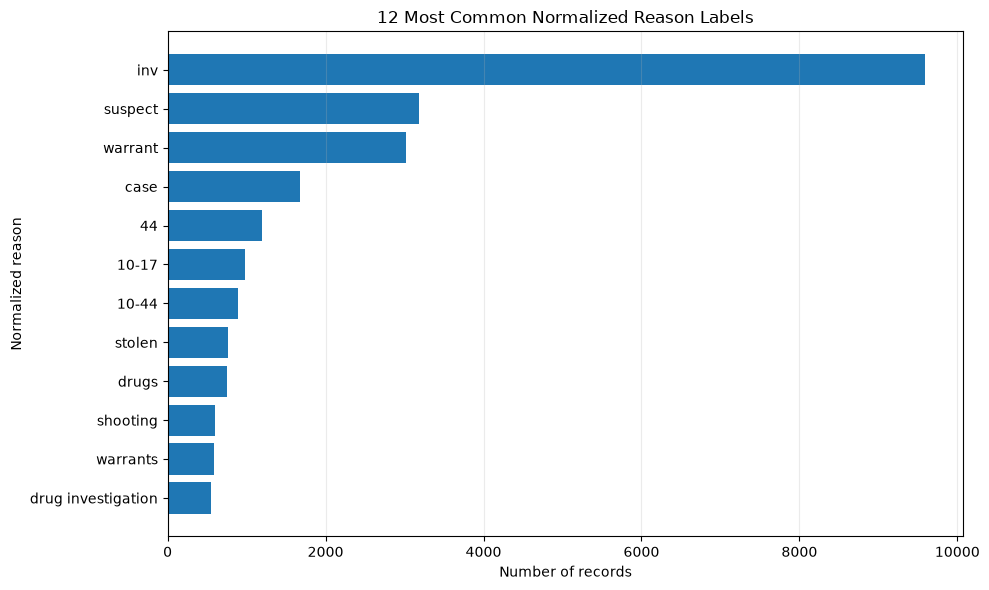

In [7]:
reason_detail = (
    analysis_df
    .groupby(["reason_category", "reason_normalized"], dropna=False)
    .size()
    .reset_index(name="Occurrences")
    .sort_values("Occurrences", ascending=False)
    .reset_index(drop=True)
)

reason_detail["Share of analysis group"] = (
    reason_detail["Occurrences"] / len(analysis_df) * 100
).round(2)

print("Most frequent normalized reason labels")
display(reason_detail.head(20))

major_categories = [
    "General Investigation",
    "BOLO / Suspect Vehicle",
    "Warrant / Wanted Person",
    "Drug Investigation",
    "Violent / Sexual Crime",
    "Stolen Vehicle / MVT"
]

category_reason_rows = []
for category_name in major_categories:
    top_reasons = (
        reason_detail[reason_detail["reason_category"] == category_name]
        .head(5)
    )
    category_reason_rows.append(top_reasons)

category_reason_summary = pd.concat(category_reason_rows, ignore_index=True)
display(category_reason_summary)

plot_reasons = reason_detail.head(12).sort_values("Occurrences")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    plot_reasons["reason_normalized"].fillna("Missing / blank").astype(str),
    plot_reasons["Occurrences"]
)
ax.set_title("12 Most Common Normalized Reason Labels")
ax.set_xlabel("Number of records")
ax.set_ylabel("Normalized reason")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Takeaway:** The label "inv" (short for investigation) shows up 9,595 times — about 1 in 4 searches. It's just an abbreviation, so we keep it mapped to its category (General Investigation) rather than guessing what it means.


## 6. Did searches go up or down by month?
Counting searches per month. A rise or drop here could mean more/less police activity — but it could also just mean better record-keeping. The data alone can't tell us which.


Monthly search-record totals


,month,Search records
0,2022-03,35
1,2022-04,97
2,2022-05,57
3,2022-06,21
4,2022-07,78
5,2022-08,53
6,2022-09,27
7,2022-10,58
8,2022-11,66
9,2022-12,57


Yearly totals within the available dataset


,Year,Search records
0,2022,549
1,2023,523
2,2024,14723
3,2025,21901


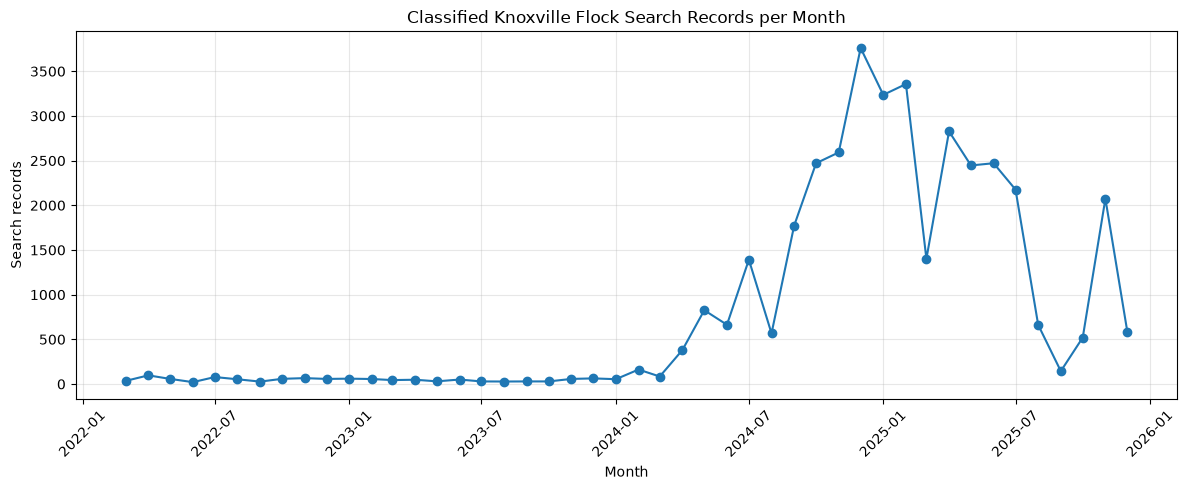

Highest month: 2024-12 (3,760 records).
Lowest month: 2022-06 (21 records).


In [8]:
monthly_counts = pd.crosstab(time_df["month"], time_df["reason_category"]).sort_index()
monthly_totals = monthly_counts.sum(axis=1)
monthly_summary = monthly_totals.rename("Search records").reset_index()
monthly_summary["month_date"] = pd.to_datetime(monthly_summary["month"])
monthly_summary["year"] = monthly_summary["month_date"].dt.year

yearly_totals = (
    time_df.groupby(time_df["search_time"].dt.year)
    .size()
    .rename("Search records")
    .reset_index()
    .rename(columns={"search_time": "Year"})
)

print("Monthly search-record totals")
display(monthly_summary[["month", "Search records"]])

print("Yearly totals within the available dataset")
display(yearly_totals)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_summary["month_date"], monthly_summary["Search records"], marker="o")
ax.set_title("Classified Knoxville Flock Search Records per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Search records")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

highest_month = monthly_totals.idxmax()
lowest_month = monthly_totals.idxmin()
print(f"Highest month: {highest_month} ({monthly_totals.max():,} records).")
print(f"Lowest month: {lowest_month} ({monthly_totals.min():,} records).")

**Takeaway:** Searches jumped a lot over time: 523 in 2023 → 14,723 in 2024 → 21,901 in 2025. We don't know if that's more actual activity or just more complete records.


## 7. Which reasons became more or less common over time?
Tracking the top 6 categories month by month — once by raw count, once by percentage, so we can tell a real shift from just "more searches overall."


Monthly counts for the six largest categories


reason_category,General Investigation,BOLO / Suspect Vehicle,Warrant / Wanted Person,No Offense Stated / Redacted,Drug Investigation,Violent / Sexual Crime
month,,,,,,
2022-03,5,1,21,0,0,0
2022-04,8,14,46,4,0,1
2022-05,4,8,13,9,0,1
2022-06,1,3,8,4,0,0
2022-07,5,14,41,4,0,6
2022-08,4,3,38,2,2,0
2022-09,5,17,1,1,0,0
2022-10,2,15,2,1,0,1
2022-11,0,25,4,7,1,1


Monthly percentage for the six largest categories


reason_category,General Investigation,BOLO / Suspect Vehicle,Warrant / Wanted Person,No Offense Stated / Redacted,Drug Investigation,Violent / Sexual Crime
month,,,,,,
2022-03,14.29,2.86,60.00,0.00,0.00,0.00
2022-04,8.25,14.43,47.42,4.12,0.00,1.03
2022-05,7.02,14.04,22.81,15.79,0.00,1.75
2022-06,4.76,14.29,38.10,19.05,0.00,0.00
2022-07,6.41,17.95,52.56,5.13,0.00,7.69
2022-08,7.55,5.66,71.70,3.77,3.77,0.00
2022-09,18.52,62.96,3.70,3.70,0.00,0.00
2022-10,3.45,25.86,3.45,1.72,0.00,1.72
2022-11,0.00,37.88,6.06,10.61,1.52,1.52


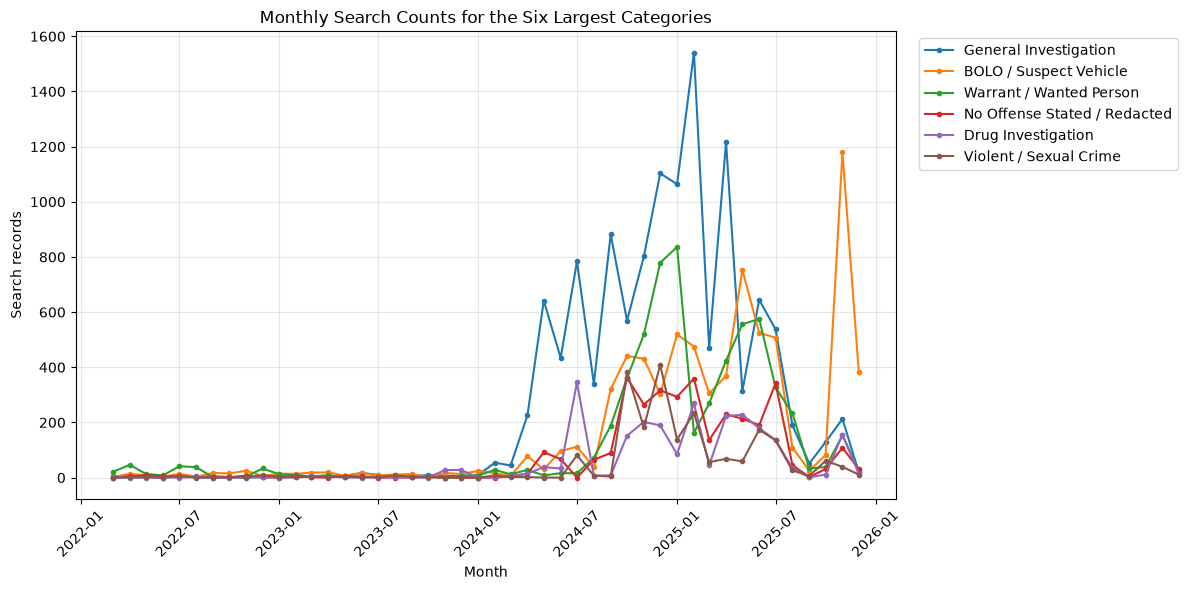

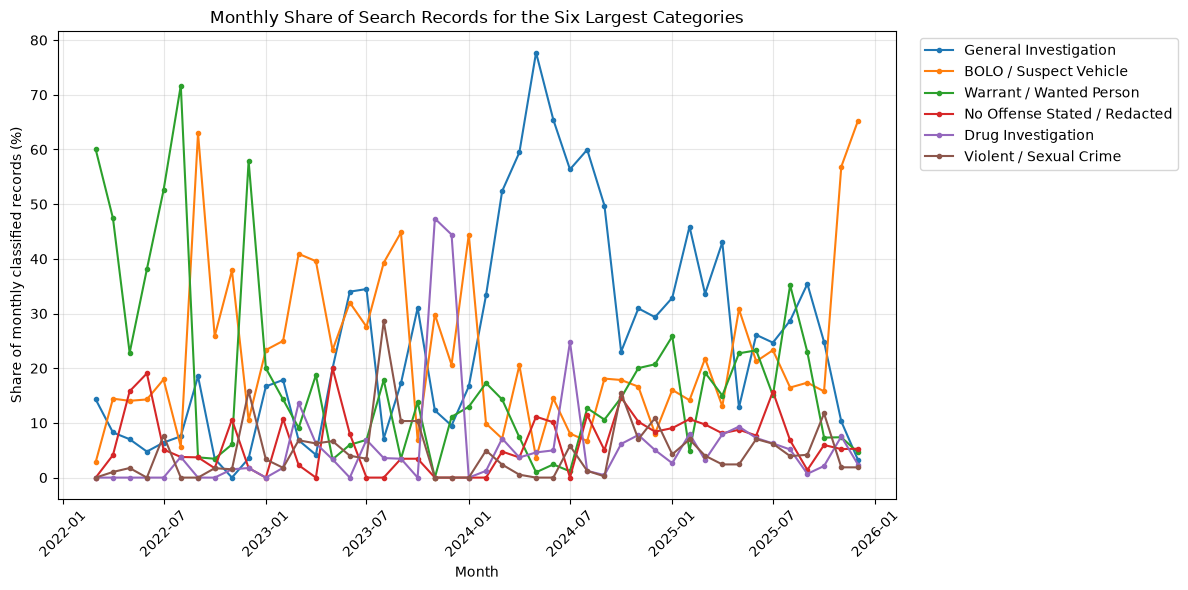

In [9]:
top_categories = reason_summary.head(6)["Category"].tolist()
monthly_top_counts = monthly_counts.reindex(columns=top_categories, fill_value=0)
monthly_top_percent = monthly_top_counts.div(monthly_totals, axis=0).mul(100)
monthly_top_percent = monthly_top_percent.round(2)

print("Monthly counts for the six largest categories")
display(monthly_top_counts)

print("Monthly percentage for the six largest categories")
display(monthly_top_percent)

monthly_dates = pd.to_datetime(monthly_top_counts.index)
fig, ax = plt.subplots(figsize=(12, 6))
for category_name in top_categories:
    ax.plot(monthly_dates, monthly_top_counts[category_name], marker="o", markersize=3, label=category_name)
ax.set_title("Monthly Search Counts for the Six Largest Categories")
ax.set_xlabel("Month")
ax.set_ylabel("Search records")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
for category_name in top_categories:
    ax.plot(monthly_dates, monthly_top_percent[category_name], marker="o", markersize=3, label=category_name)
ax.set_title("Monthly Share of Search Records for the Six Largest Categories")
ax.set_xlabel("Month")
ax.set_ylabel("Share of monthly classified records (%)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Takeaway:**
- General Investigation spiked in May 2024 (78% of that month's searches).
- BOLO/Suspect Vehicle took over in late 2025 (65% of December 2025's searches).
- Drug Investigation peaked in July 2024 (345 records).


## 8. Were busy months busy every day, or just one day?
A high monthly total could come from one huge day. This checks how spread out the activity actually was.


Selected months for closer review


,month,total_searches,active_days,average_per_active_day,median_per_active_day,busiest_day_count,calendar_days,active_day_percentage,busiest_date
26,2024-05,826,24,34.42,31.0,138,31,77.42,2024-05-29
28,2024-07,1391,26,53.50,36.5,229,31,83.87,2024-07-18
30,2024-09,1773,26,68.19,41.5,295,30,86.67,2024-09-19
31,2024-10,2471,31,79.71,55.0,250,31,100.00,2024-10-15
32,2024-11,2592,30,86.40,75.0,187,30,100.00,2024-11-06
33,2024-12,3760,31,121.29,96.0,897,31,100.00,2024-12-29
41,2025-08,662,29,22.83,13.0,109,31,93.55,2025-08-17
42,2025-09,144,24,6.00,5.0,17,30,80.00,2025-09-24
43,2025-10,520,29,17.93,12.0,77,31,93.55,2025-10-29
44,2025-11,2074,30,69.13,60.0,256,30,100.00,2025-11-15


Months with the highest average searches per active day


,month,total_searches,active_days,average_per_active_day,median_per_active_day,busiest_day_count,calendar_days,active_day_percentage,busiest_date
33,2024-12,3760,31,121.29,96.0,897,31,100.0,2024-12-29
35,2025-02,3357,28,119.89,83.0,406,28,100.0,2025-02-19
34,2025-01,3236,31,104.39,102.0,283,31,100.0,2025-01-26
37,2025-04,2827,30,94.23,73.0,281,30,100.0,2025-04-11
32,2024-11,2592,30,86.40,75.0,187,30,100.0,2024-11-06
39,2025-06,2471,30,82.37,67.5,199,30,100.0,2025-06-04
31,2024-10,2471,31,79.71,55.0,250,31,100.0,2024-10-15
38,2025-05,2446,31,78.90,73.0,166,31,100.0,2025-05-02
40,2025-07,2176,31,70.19,58.0,206,31,100.0,2025-07-01
44,2025-11,2074,30,69.13,60.0,256,30,100.0,2025-11-15


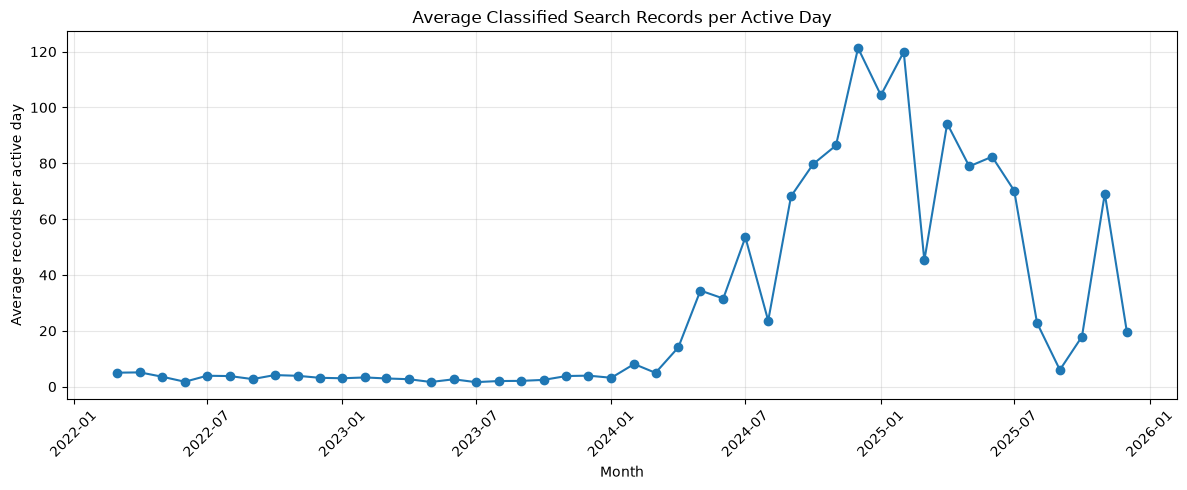

In [10]:
daily = (
    time_df.groupby("date")
    .size()
    .rename("daily_searches")
    .reset_index()
)
daily["month"] = daily["date"].str[:7]
daily["search_date"] = pd.to_datetime(daily["date"])

monthly_daily_stats = (
    daily.groupby("month")
    .agg(
        total_searches=("daily_searches", "sum"),
        active_days=("date", "nunique"),
        average_per_active_day=("daily_searches", "mean"),
        median_per_active_day=("daily_searches", "median"),
        busiest_day_count=("daily_searches", "max")
    )
    .reset_index()
)

monthly_daily_stats["calendar_days"] = monthly_daily_stats["month"].apply(
    lambda month: pd.Period(month).days_in_month
)
monthly_daily_stats["active_day_percentage"] = (
    monthly_daily_stats["active_days"] / monthly_daily_stats["calendar_days"] * 100
).round(2)

busiest_dates = daily.loc[
    daily.groupby("month")["daily_searches"].idxmax(),
    ["month", "date"]
].rename(columns={"date": "busiest_date"})

monthly_daily_stats = monthly_daily_stats.merge(busiest_dates, on="month", how="left")

months_of_interest = [
    "2024-05", "2024-07", "2024-09", "2024-10", "2024-11", "2024-12",
    "2025-08", "2025-09", "2025-10", "2025-11", "2025-12"
]

print("Selected months for closer review")
display(
    monthly_daily_stats[
        monthly_daily_stats["month"].isin(months_of_interest)
    ].round(2)
)

print("Months with the highest average searches per active day")
display(
    monthly_daily_stats.sort_values(
        "average_per_active_day", ascending=False
    ).head(10).round(2)
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    pd.to_datetime(monthly_daily_stats["month"]),
    monthly_daily_stats["average_per_active_day"],
    marker="o"
)
ax.set_title("Average Classified Search Records per Active Day")
ax.set_xlabel("Month")
ax.set_ylabel("Average records per active day")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Takeaway:** September 2025 was quiet overall — only 6 records a day on average. December 2024 looked busy, but it turns out almost 900 of those records came from a single day (Dec 29). More on that next.


## 9. Looking closer at the unusual days
What happened on the busiest days, and was that late-2025 BOLO increase a one-day thing or spread across the month?


15 busiest dates


reason_category,date,BOLO / Suspect Vehicle,Drug Investigation,General Investigation,Misc / Other,Missing / Endangered Person,No Offense Stated / Redacted,Property Crime,Routine / Administrative / Test,Stolen Vehicle / MVT,Traffic / Crash,Violent / Sexual Crime,Warrant / Wanted Person,TOTAL
0,2024-12-29,86,0,14,0,102,84,0,20,166,0,309,116,897
1,2025-02-19,20,0,238,0,0,45,8,0,7,0,88,0,406
2,2025-02-10,2,7,245,0,8,11,1,0,2,11,0,47,334
3,2024-09-19,32,0,169,0,0,0,91,0,3,0,0,0,295
4,2025-01-26,127,0,5,0,0,0,0,0,10,0,1,140,283
5,2025-02-24,2,2,263,0,0,6,0,0,0,8,0,0,281
6,2025-04-11,28,0,170,0,0,25,0,5,6,12,13,22,281
7,2024-09-18,10,0,113,0,0,0,18,5,19,0,0,111,276
8,2025-02-18,12,0,120,0,0,80,0,8,0,2,51,2,275
9,2025-02-04,78,0,32,0,0,50,16,0,0,0,80,11,267


Category breakdown for 2024-12-29: 897 records


,Category,Records,Share of date's records (%)
0,Violent / Sexual Crime,309,34.45
1,Stolen Vehicle / MVT,166,18.51
2,Warrant / Wanted Person,116,12.93
3,Missing / Endangered Person,102,11.37
4,BOLO / Suspect Vehicle,86,9.59
5,No Offense Stated / Redacted,84,9.36
6,Routine / Administrative / Test,20,2.23
7,General Investigation,14,1.56


Most common normalized labels on the spike date


,reason_category,reason_normalized,Records
14,Violent / Sexual Crime,kidnapping,304
12,Stolen Vehicle / MVT,stolen,166
17,Warrant / Wanted Person,warrant,99
5,Missing / Endangered Person,missing,88
9,No Offense Stated / Redacted,kidapping,81
2,BOLO / Suspect Vehicle,suspect,45
1,BOLO / Suspect Vehicle,sus,39
16,Warrant / Wanted Person,wanted,17
11,Routine / Administrative / Test,test,15
6,Missing / Endangered Person,missing person,14


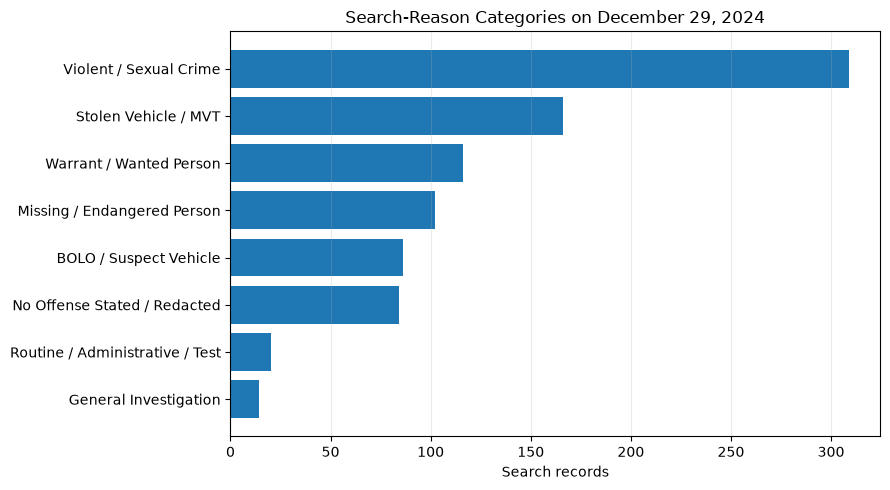

November 2025 BOLO summary
Total BOLO records: 1,179
Days with BOLO records: 29
Most common normalized label: suspect
Occurrences of that label: 995


,date,BOLO records
14,2025-11-15,229
18,2025-11-19,121
26,2025-11-28,114
15,2025-11-16,102
10,2025-11-11,95
13,2025-11-14,73
5,2025-11-06,60
9,2025-11-10,51
2,2025-11-03,45
4,2025-11-05,43


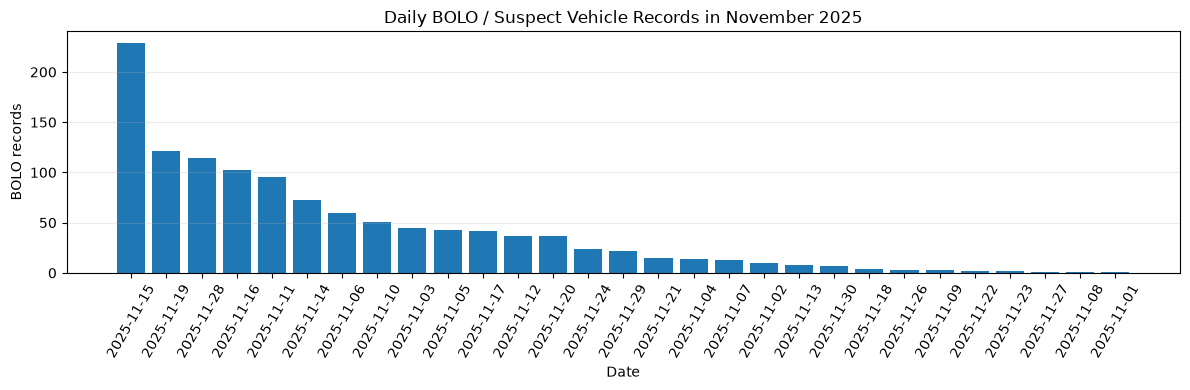

In [11]:
daily_category_counts = pd.crosstab(time_df["date"], time_df["reason_category"])
daily_category_counts["TOTAL"] = daily_category_counts.sum(axis=1)
top_days = daily_category_counts.sort_values("TOTAL", ascending=False).head(15)

print("15 busiest dates")
display(top_days.reset_index())

spike_date = "2024-12-29"
spike_records = time_df[time_df["date"] == spike_date]
spike_category_counts = (
    spike_records["reason_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Records")
)
spike_category_counts["Share of date's records (%)"] = (
    spike_category_counts["Records"] / len(spike_records) * 100
).round(2)

print(f"Category breakdown for {spike_date}: {len(spike_records):,} records")
display(spike_category_counts)

print("Most common normalized labels on the spike date")
display(
    spike_records.groupby(["reason_category", "reason_normalized"], dropna=False)
    .size()
    .rename("Records")
    .reset_index()
    .sort_values("Records", ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(9, 5))
spike_plot = spike_category_counts.sort_values("Records")
ax.barh(spike_plot["Category"], spike_plot["Records"])
ax.set_title("Search-Reason Categories on December 29, 2024")
ax.set_xlabel("Search records")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

november_bolo = time_df[
    time_df["month"].eq("2025-11")
    & time_df["reason_category"].eq("BOLO / Suspect Vehicle")
]
november_bolo_daily = (
    november_bolo.groupby("date")
    .size()
    .rename("BOLO records")
    .reset_index()
    .sort_values("BOLO records", ascending=False)
)

november_bolo_reason = november_bolo["reason_normalized"].value_counts(dropna=False)

print("November 2025 BOLO summary")
print("Total BOLO records:", f"{len(november_bolo):,}")
print("Days with BOLO records:", f"{november_bolo['date'].nunique():,}")
print("Most common normalized label:", november_bolo_reason.index[0])
print("Occurrences of that label:", f"{november_bolo_reason.iloc[0]:,}")
display(november_bolo_daily.head(12))

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(november_bolo_daily["date"], november_bolo_daily["BOLO records"])
ax.set_title("Daily BOLO / Suspect Vehicle Records in November 2025")
ax.set_xlabel("Date")
ax.set_ylabel("BOLO records")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

**Takeaway:**
- **Dec 29, 2024 was a huge outlier** — 897 records in one day (nearly a quarter of that month), mostly kidnapping, stolen vehicle, warrant, and missing person reasons. This looks like one unusual event, not a normal day.
- **The November 2025 BOLO surge was NOT just one day** — 1,179 BOLO records spread across 29 different days, mostly labeled "suspect." Something changed for the whole month, though the data doesn't tell us why.


## 10. What time of day do searches happen?
Looking at what hour and what weekday searches get logged (Knoxville time).


Search records by hour (Knoxville local time)


,hour,Search records
0,0,1011
1,1,845
2,2,454
3,3,222
4,4,231
5,5,226
6,6,382
7,7,704
8,8,1450
9,9,1724


Search records by weekday


,weekday,Search records
0,Monday,6413
1,Tuesday,6206
2,Wednesday,6107
3,Thursday,5566
4,Friday,5391
5,Saturday,3268
6,Sunday,4745


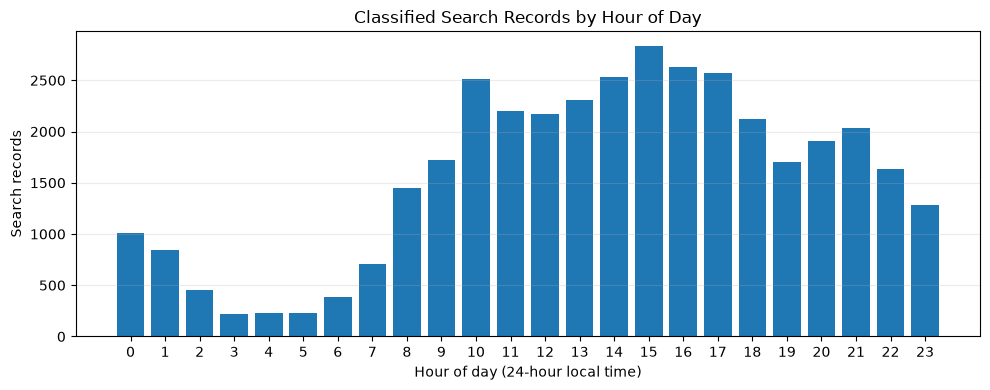

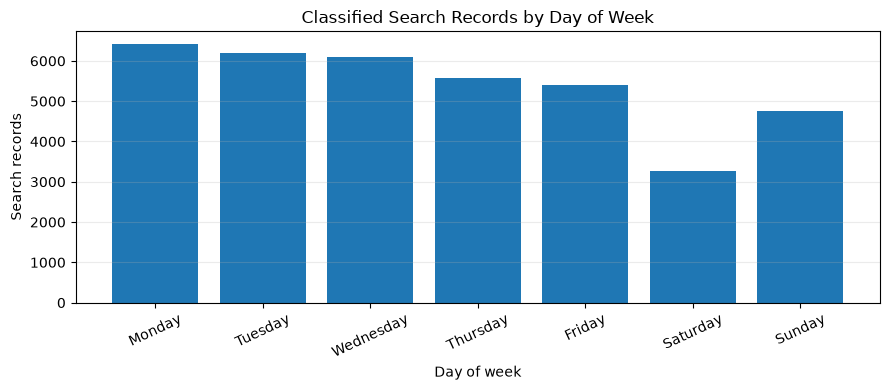

Busiest hour: 15:00 (2,836 records).
Quietest hour: 03:00 (222 records).
Busiest weekday: Monday (6,413 records).
Fewest records: Saturday (3,268 records).


In [12]:
hour_counts = time_df["hour"].value_counts().sort_index()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = time_df["weekday"].value_counts().reindex(weekday_order, fill_value=0)

print("Search records by hour (Knoxville local time)")
display(hour_counts.rename("Search records").reset_index().rename(columns={"index": "Hour"}))

print("Search records by weekday")
display(weekday_counts.rename("Search records").reset_index().rename(columns={"index": "Weekday"}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hour_counts.index, hour_counts.values)
ax.set_title("Classified Search Records by Hour of Day")
ax.set_xlabel("Hour of day (24-hour local time)")
ax.set_ylabel("Search records")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekday_counts.index, weekday_counts.values)
ax.set_title("Classified Search Records by Day of Week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Search records")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

peak_hour = int(hour_counts.idxmax())
lowest_hour = int(hour_counts.idxmin())
peak_weekday = weekday_counts.idxmax()
lowest_weekday = weekday_counts.idxmin()
print(f"Busiest hour: {peak_hour:02d}:00 ({hour_counts.max():,} records).")
print(f"Quietest hour: {lowest_hour:02d}:00 ({hour_counts.min():,} records).")
print(f"Busiest weekday: {peak_weekday} ({weekday_counts.max():,} records).")
print(f"Fewest records: {lowest_weekday} ({weekday_counts.min():,} records).")

**Takeaway:** 3 PM is the busiest hour, 3 AM the quietest. Monday has the most searches, Saturday the fewest.


## 11. How long a time window does each search cover?
Each record has a start and end date — that's the range of time the search was looking at, not how long an officer spent on it.


,Measure,Value
0,Records with both timeframe values,"37,696"
1,Median window (days),29.65
2,Average window (days),20.21
3,75th percentile (days),30.00
4,90th percentile (days),30.00
5,Longest window (days),635.00


,Timeframe window,Records,Percentage
0,Up to 1 day,8375,22.22
1,More than 1–7 days,7615,20.20
2,More than 7–30 days,19381,51.41
3,More than 30–90 days,1867,4.95
4,Over 90 days,458,1.21


,reason_category,Records,Median_days,Average_days
0,General Investigation,12402,30.00,24.16
1,BOLO / Suspect Vehicle,7385,7.00,18.14
2,Warrant / Wanted Person,5930,7.00,14.98
3,No Offense Stated / Redacted,3306,25.00,21.20
4,Drug Investigation,2451,30.00,17.90
5,Violent / Sexual Crime,2131,28.00,18.20
6,Stolen Vehicle / MVT,1575,14.00,17.52
7,Property Crime,917,30.00,23.44
8,Routine / Administrative / Test,824,30.00,31.01
9,Traffic / Crash,481,9.13,15.99


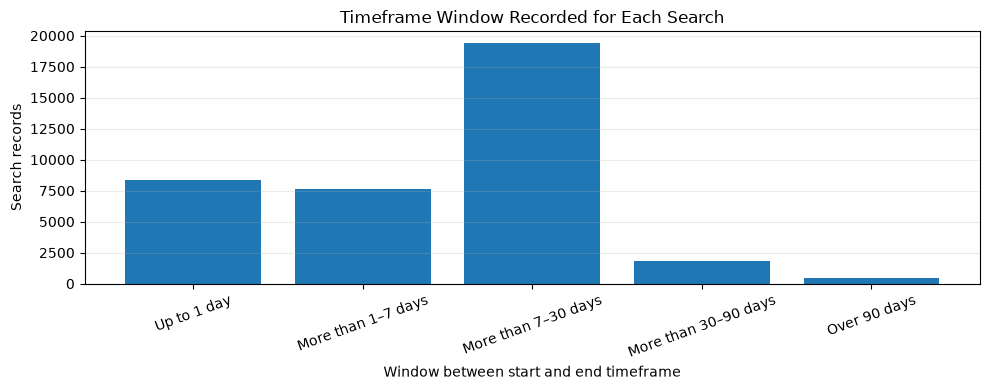

In [13]:
start_time = pd.to_datetime(time_df["start_timeframe_utc"], utc=True, errors="coerce")
end_time = pd.to_datetime(time_df["end_timeframe_utc"], utc=True, errors="coerce")
time_df["timeframe_days"] = (end_time - start_time).dt.total_seconds() / 86400

valid_windows = time_df["timeframe_days"].dropna()
window_summary = pd.DataFrame({
    "Measure": ["Records with both timeframe values", "Median window (days)", "Average window (days)", "75th percentile (days)", "90th percentile (days)", "Longest window (days)"],
    "Value": [
        f"{len(valid_windows):,}",
        f"{valid_windows.median():.2f}",
        f"{valid_windows.mean():.2f}",
        f"{valid_windows.quantile(0.75):.2f}",
        f"{valid_windows.quantile(0.90):.2f}",
        f"{valid_windows.max():.2f}"
    ]
})

display(window_summary)

window_bins = [-np.inf, 1, 7, 30, 90, np.inf]
window_labels = ["Up to 1 day", "More than 1–7 days", "More than 7–30 days", "More than 30–90 days", "Over 90 days"]
time_df["timeframe_group"] = pd.cut(
    time_df["timeframe_days"],
    bins=window_bins,
    labels=window_labels
)

window_counts = (
    time_df["timeframe_group"]
    .value_counts()
    .reindex(window_labels, fill_value=0)
    .rename_axis("Timeframe window")
    .reset_index(name="Records")
)
window_counts["Percentage"] = (
    window_counts["Records"] / len(valid_windows) * 100
).round(2)

display(window_counts)

category_windows = (
    time_df.groupby("reason_category", observed=True)["timeframe_days"]
    .agg(Records="count", Median_days="median", Average_days="mean")
    .sort_values("Records", ascending=False)
    .round(2)
    .reset_index()
)
display(category_windows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(window_counts["Timeframe window"], window_counts["Records"])
ax.set_title("Timeframe Window Recorded for Each Search")
ax.set_xlabel("Window between start and end timeframe")
ax.set_ylabel("Search records")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Takeaway:** Typical window is about 30 days. General Investigation searches tend to cover ~30 days, while BOLO and Warrant searches are shorter, around 7 days.


## 12. What "type" of search is logged?
Just reporting the raw labels in the data (like "lookup" vs "search") — no extra interpretation since the project doesn't define what each one means.


,Search type,Records,Percentage
0,lookup,16349,43.37
1,search,12829,34.03
2,Not recorded,8471,22.47
3,convoy,32,0.08
4,multiGeo,15,0.04


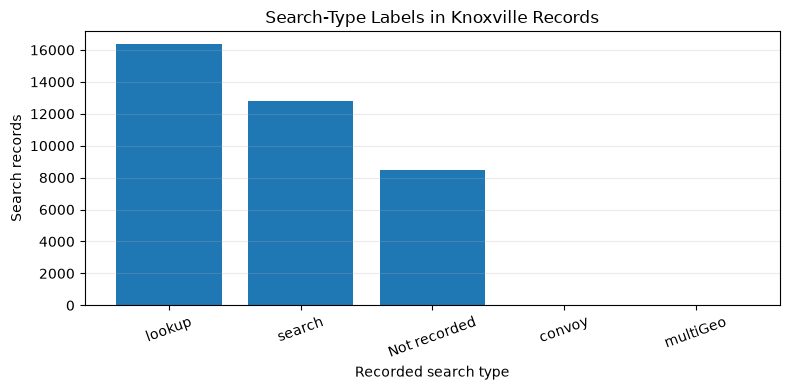

In [14]:
search_type_counts = (
    time_df["search_type"]
    .fillna("Not recorded")
    .value_counts()
    .rename_axis("Search type")
    .reset_index(name="Records")
)
search_type_counts["Percentage"] = (
    search_type_counts["Records"] / len(time_df) * 100
).round(2)

display(search_type_counts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(search_type_counts["Search type"], search_type_counts["Records"])
ax.set_title("Search-Type Labels in Knoxville Records")
ax.set_xlabel("Recorded search type")
ax.set_ylabel("Search records")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 13. Wrapping it all up


In [15]:
top_category = reason_summary.iloc[0]
second_category = reason_summary.iloc[1]
third_category = reason_summary.iloc[2]
inv_count = int((analysis_df["reason_normalized"] == "inv").sum())
december_total = int(monthly_totals.get("2024-12", 0))
december_spike_total = int((time_df["date"] == "2024-12-29").sum())
november_bolo_total = int(len(november_bolo))
november_total = int(monthly_totals.get("2025-11", 0))
november_bolo_share = november_bolo_total / november_total * 100 if november_total else np.nan
september_2025 = monthly_daily_stats[monthly_daily_stats["month"] == "2025-09"].iloc[0]

print("KNOXVILLE FLOCK ANALYSIS: KEY RESULTS")
print(
    f"1. {top_category['Category']} is the largest category: "
    f"{top_category['Records']:,} records ({top_category['Percentage']:.2f}%)."
)
print(
    f"2. The next two largest categories are {second_category['Category']} "
    f"({second_category['Records']:,}) and {third_category['Category']} "
    f"({third_category['Records']:,})."
)
print(
    f"3. The normalized reason label 'inv' appears {inv_count:,} times "
    f"({inv_count / len(analysis_df) * 100:.2f}% of the analysis group)."
)
print(
    f"4. December 29, 2024 has {december_spike_total:,} records, "
    f"{december_spike_total / december_total * 100:.2f}% of December 2024's classified total."
)
print(
    f"5. BOLO / Suspect Vehicle accounts for {november_bolo_total:,} records "
    f"({november_bolo_share:.2f}%) in November 2025."
)
print(
    f"6. September 2025 averages {september_2025['average_per_active_day']:.2f} "
    f"records per active day, with activity on {int(september_2025['active_days'])} "
    f"of {int(september_2025['calendar_days'])} calendar days."
)
print(
    f"7. The busiest recorded hour is {peak_hour:02d}:00, and the busiest weekday is {peak_weekday}."
)
print(
    f"8. The median recorded timeframe window is {valid_windows.median():.2f} days."
)

KNOXVILLE FLOCK ANALYSIS: KEY RESULTS
1. General Investigation is the largest category: 12,402 records (32.90%).
2. The next two largest categories are BOLO / Suspect Vehicle (7,385) and Warrant / Wanted Person (5,930).
3. The normalized reason label 'inv' appears 9,595 times (25.45% of the analysis group).
4. December 29, 2024 has 897 records, 23.86% of December 2024's classified total.
5. BOLO / Suspect Vehicle accounts for 1,179 records (56.85%) in November 2025.
6. September 2025 averages 6.00 records per active day, with activity on 24 of 30 calendar days.
7. The busiest recorded hour is 15:00, and the busiest weekday is Monday.
8. The median recorded timeframe window is 29.65 days.


## Bottom line

Knoxville's Flock searches are mostly logged as General Investigation, BOLO/Suspect Vehicle, and Warrant/Wanted Person. The mix shifts over time — General Investigation led in parts of 2024, BOLO took over in late 2025. There's one big one-day spike (Dec 29, 2024) and one unusually quiet stretch (Sept 2025).

**Keep in mind:**
- These are search records, not confirmed crimes or arrests.
- Reasons are free-text, sorted into categories — abbreviations might hide more detail.
- The main numbers exclude "Malformed / Unintelligible" entries, so percentages are out of 37,696 records, not all 71,501.
- The big jump in 2024–2025 could be more real activity, or just better data collection — can't tell from this alone.
- The Dec 29 spike is a one-time event, not a typical day.
- The "time window" is the date range in the record, not how long someone actually worked the case.

**One-paragraph summary:** Knoxville has 71,501 total Flock search records; 37,696 have a usable category. The top three are General Investigation (12,402, 32.9%), BOLO/Suspect Vehicle (7,385, 19.6%), and Warrant/Wanted Person (5,930, 15.7%). Search volume grew a lot from 2023 to 2025, the reason mix shifted over time, and there's one major outlier day (Dec 29, 2024).
